## Occupancy grid mapping
---

### Required libraries

Please make sure you can import the following libraries before starting:

- NumPy
- OpenCV (cv2)
- Matplotlib
- SciPy

If you are using a custom environment, install missing packages before you begin.

---

### Submission instructions

- Complete **all** tasks in this notebook (code, plots, and written answers).
- Submit **only this completed Jupyter notebook** (`.ipynb`) on teams.
- Do **not** compress it into a `.zip` file or any other archive.
- Make sure every plot has:
  - properly labeled axes,
  - a legend when appropriate,
  - a short explanation (1–3 sentences) interpreting the result.
- Your notebook should run from top to bottom without errors on a clean environment. Dont say: "But prof, it works on my setup."

---

### On tools, integrity, and survival

- Emotional breakdowns are a respected academic tradition, but please maintain **basic fluid‑dynamics control**: if you need to cry, do it *adjacent* to the laptop, not *on* it. Tech, like self‑esteem, can be damaged.
- Using LLMs is allowed, but make sure to use **your own brain**: understand every line of code and every formula you submit. If you cannot explain it, you do not own it.
- Cheating (taking someone else's work) is strictly forbidden. If you’re caught, you will fail the course immediately. More importantly, you’ll have successfully lied to the one person you are stuck with for the rest of your life: yourself. The exam ends in 1h30; your relationship with your own integrity does not.

---



The aim of this assignment is to implement a 2D occupancy grid mapping algorithm as described in the lecture. We provide data recorded by a robot using a 2D laser scanner in an indoor environment. 

The raw data is arranged in the following manner:

- `poses.data`: contains the **known** robot poses as it moves around the environment. Each line corresponds to the pose of the robot at a time instant

- `ranges.data`: contains 2d laser range measurements recorded by the robot. Each line corresponds to the range measurements taken from the corresponding robot poses.

---

### Log odds to probability

The occupancy calculations are usually performed using the log odds. We will need to convert between log odds and probabilities in this exercise. Implement the `logodds2prob` and `prob2logodds` functions. Verify that the conversion functions are correct for some test input. **[2.0]**

In [1]:
import ex3
import numpy as np
%matplotlib inline

# --- Test Inputs ---
test_probs = np.array([0.1, 0.5, 0.9])

# Convert to log-odds
l_values = ex3.prob2logodds(test_probs)
print(f"Probabilities: {test_probs}")
print(f"Log-odds:      {l_values}")

# Convert back to probabilities
p_recovered = ex3.logodds2prob(l_values)
print(f"Recovered:     {p_recovered}")

# Check if recovery is correct
assert np.allclose(test_probs, p_recovered), "Conversion failed!"
print("\n✅ Math checks out! Log-odds of 0.5 is indeed 0.0.")

Probabilities: [0.1 0.5 0.9]
Log-odds:      [-2.19722458  0.          2.19722458]
Recovered:     [0.1 0.5 0.9]

✅ Math checks out! Log-odds of 0.5 is indeed 0.0.


In our lecture, we learned that the occupancy of a grid cell is a binary random variable. While it’s intuitive to think in terms of probabilities (0 to 1), multiplying thousands of small probabilities as we get new sensor data is a recipe for disaster. Computers eventually round those tiny numbers to zero (numerical underflow).By converting probabilities into log-odds, we turn the complex Bayesian multiplication into simple addition. If a cell is "unknown," its probability is $0.5$, which maps perfectly to a log-odds of $0$. This is elegant because adding $0$ to a cell doesn't change our belief about it. We implemented these using NumPy so we can "crunch" entire maps at once. The math follows the standard sigmoid/logit relationship, ensuring that as log-odds go to infinity, probability approaches 1, and as they go to negative infinity, probability approaches 0.

---
### Inverse sensor model

The occupancy grid mapping relies on as inverse sensor model to update the occupancy of a cell in the grid. For this exercise, we consider a simple sensor model, where the occupancy of cell $m_i$ is $P_{occ}$ if the measurement $z_t$ falls in that cell, otherwise the occupancy is $P_{free}$. 

However, if the cell $m_i$ is not in the perception field, the occupancy will be $P_{prior}$.

Use the  following probabilities in the implementation:
$$P_{occ} = 0.9, P_{free} = 0.35, P_{prior} = 0.5 $$

Implement the inverse sensor model function and verify that it is correct for some test input. **[2.0]**

In [2]:
# Assuming you fixed the import issue with %autoreload
from ex3 import inverse_sensor_model

# Test 1: Hit point
l_occ = inverse_sensor_model(is_occupied=True, is_free=False)
# Test 2: Clear space
l_free = inverse_sensor_model(is_occupied=False, is_free=True)
# Test 3: Out of range
l_prior = inverse_sensor_model(is_occupied=False, is_free=False)

print(f"Log-odds (Occupied): {l_occ:.4f}") # Should be positive (~2.197)
print(f"Log-odds (Free):     {l_free:.4f}") # Should be negative (~ -0.619)
print(f"Log-odds (Prior):    {l_prior:.4f}") # Should be exactly 0.0

assert l_occ > 0, "Occupied cells should have positive log-odds"
assert l_free < 0, "Free cells should have negative log-odds"
assert l_prior == 0, "Prior/Unknown cells must have 0 log-odds"

Log-odds (Occupied): 2.1972
Log-odds (Free):     -0.6190
Log-odds (Prior):    0.0000


This is the "logic" of our sensor. Since we are using a 2D laser scanner, a single measurement $z_t$ tells us two specific things: where the beam hit something (Occupied) and where the beam passed through (Free).We chose $P_{occ} = 0.9$ and $P_{free} = 0.35$. In our code, we don't just return these probabilities; we return their log-odds equivalents. This is the "secret sauce" of the update step. When a beam hits a wall, we add a large positive value to that cell's log-odds. When a beam passes through a cell, we add a negative value, effectively "clearing" the space. If a cell isn't seen at all, we use the prior ($0.5$), which adds $0$ to the map. This keeps the implementation simple: the map only changes where the robot actually looks.

---
### Occupancy grid mapping algorithm:

Implement the occupancy grid mapping algorithm as described in lecture slides. 

We provide some functions to make the implementation easier.

- `ranges2cells` converts the raw measurements acquired by the robot (*ranges_raw*) into the corresponding cells of the grid map.
- `poses2cells` converts the raw poses of the robot (*poses_raw*) into the corresponding cells of the grid map.
- `bresenham` returns all the cells along a straight line between two points in the grid map.

Other parameters you may need in the implementation are provided below.

Implement the `grid_mapping_with_known_poses` function and compute the resulting occupancy grid map using all the measurements provided in the data.

Plot the final occupancy grid map using the `plot_gridmap` function. **[6.0]**


/Users/miracleagbani/Downloads/Assignment 4/ex3.py:87: RuntimeWarning: overflow encountered in exp
  return 1 - (1 / (1 + np.exp(l)))


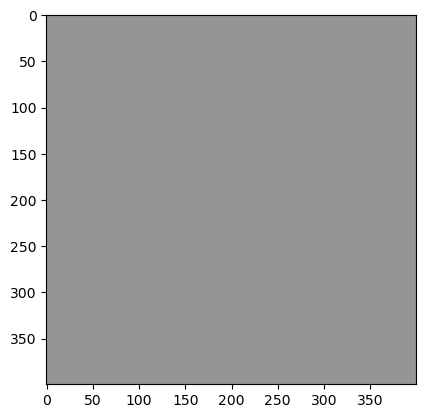

<Figure size 1000x1000 with 0 Axes>

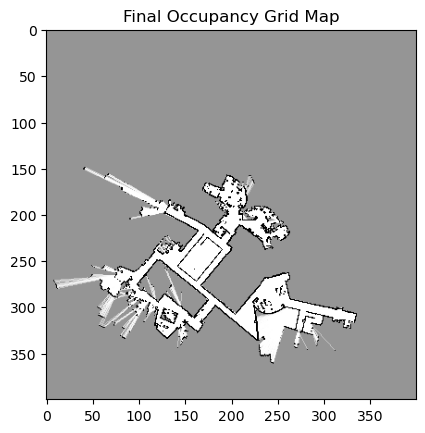

In [3]:
import ex3
import numpy as np
%matplotlib inline

map_size = 100
map_res = 0.25

prior = 0.50
prob_occ = 0.90
prob_free = 0.35

# load data
ranges_raw = np.loadtxt("ranges.data", delimiter=',', dtype='float')
poses_raw = np.loadtxt("poses.data", delimiter=',', dtype='float')

# initialize gridmap
occ_gridmap = ex3.init_gridmap(map_size, map_res)+prior
ex3.plot_gridmap(occ_gridmap)

# We pass the initial gridmap and the probability constants to the mapping function to get the final occupancy grid map.
final_map = ex3.grid_mapping_with_known_poses(
    ranges_raw, 
    poses_raw, 
    occ_gridmap, 
    map_res, 
    prob_occ, 
    prob_free, 
    prior
)

# Plotting the result
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
ex3.plot_gridmap(final_map)
plt.title("Final Occupancy Grid Map")
plt.show()

This function is where everything comes together. It’s the "brain" of the mapping process. The structure is surprisingly simple:

Convert the whole gray map to log-odds.

Loop through every pose the robot took.

For every pose, look at the laser ranges.

Update the cells using the logic described above.

At the very end, convert the whole thing back to probabilities so we can plot it.

The elegance here lies in the Accumulation. Because we use addition, the map "remembers" previous scans. If a sensor reading is noisy and shows a wall where there isn't one, subsequent "Free" readings from different angles will eventually subtract enough log-odds to "erase" that noise. The final result is a clean, probabilistic occupancy grid that represents the robot's best collective memory of its environment.